In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
air_quality_data = pd.read_csv("merged_complete_datasets/berlin_air_quality_master_2025_2026.csv")

air_quality_data.head()

,datetime,station,core,component,period,value,station_name,station_type
0,2024-12-31 23:00:00+00:00,mc010,ebc,ebc_24h,24h,0.5,Wedding,Urban background
1,2024-12-31 23:00:00+00:00,mc010,no2,no2_24h,24h,9.0,Wedding,Urban background
2,2024-12-31 23:00:00+00:00,mc010,no,no_24h,24h,2.0,Wedding,Urban background
3,2024-12-31 23:00:00+00:00,mc010,nox,nox_24h,24h,12.0,Wedding,Urban background
4,2024-12-31 23:00:00+00:00,mc010,o3,o3_24h,24h,49.0,Wedding,Urban background


In [6]:
# Check available pollutants and their data coverage
air_quality_overview = air_quality_data.groupby("component").agg(
    observations=("value", "count"),
    stations=("station", "nunique"),
    first_observation=("datetime", "min"),
    last_observation=("datetime", "max"),
    average_value=("value", "mean"),
    median_value=("value", "median")
).reset_index()

# Display the overview
display(
    air_quality_overview.sort_values("component").round(2)
)

,component,observations,stations,first_observation,last_observation,average_value,median_value
0,co_24h,1899,3,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,0.29,0.3
1,ebc_24h,2360,4,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,0.87,0.6
2,no2_24h,9684,15,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,15.66,13.0
3,no_24h,9684,15,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,6.26,2.0
4,nox_24h,9684,15,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,24.10,17.0
5,o3_24h,5179,8,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,50.71,52.0
6,pm10_24h,7713,12,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,18.66,16.0
7,pm2_24h,7713,12,2024-12-31 23:00:00+00:00,2026-10-20 22:00:00+00:00,11.83,9.0


In [8]:
# Convert datetime column to timezone-aware datetime
air_quality_data["datetime"] = pd.to_datetime(
    air_quality_data["datetime"],
    utc=True
)

# Verify the data type
print(air_quality_data["datetime"].dtype)

datetime64[us, UTC]


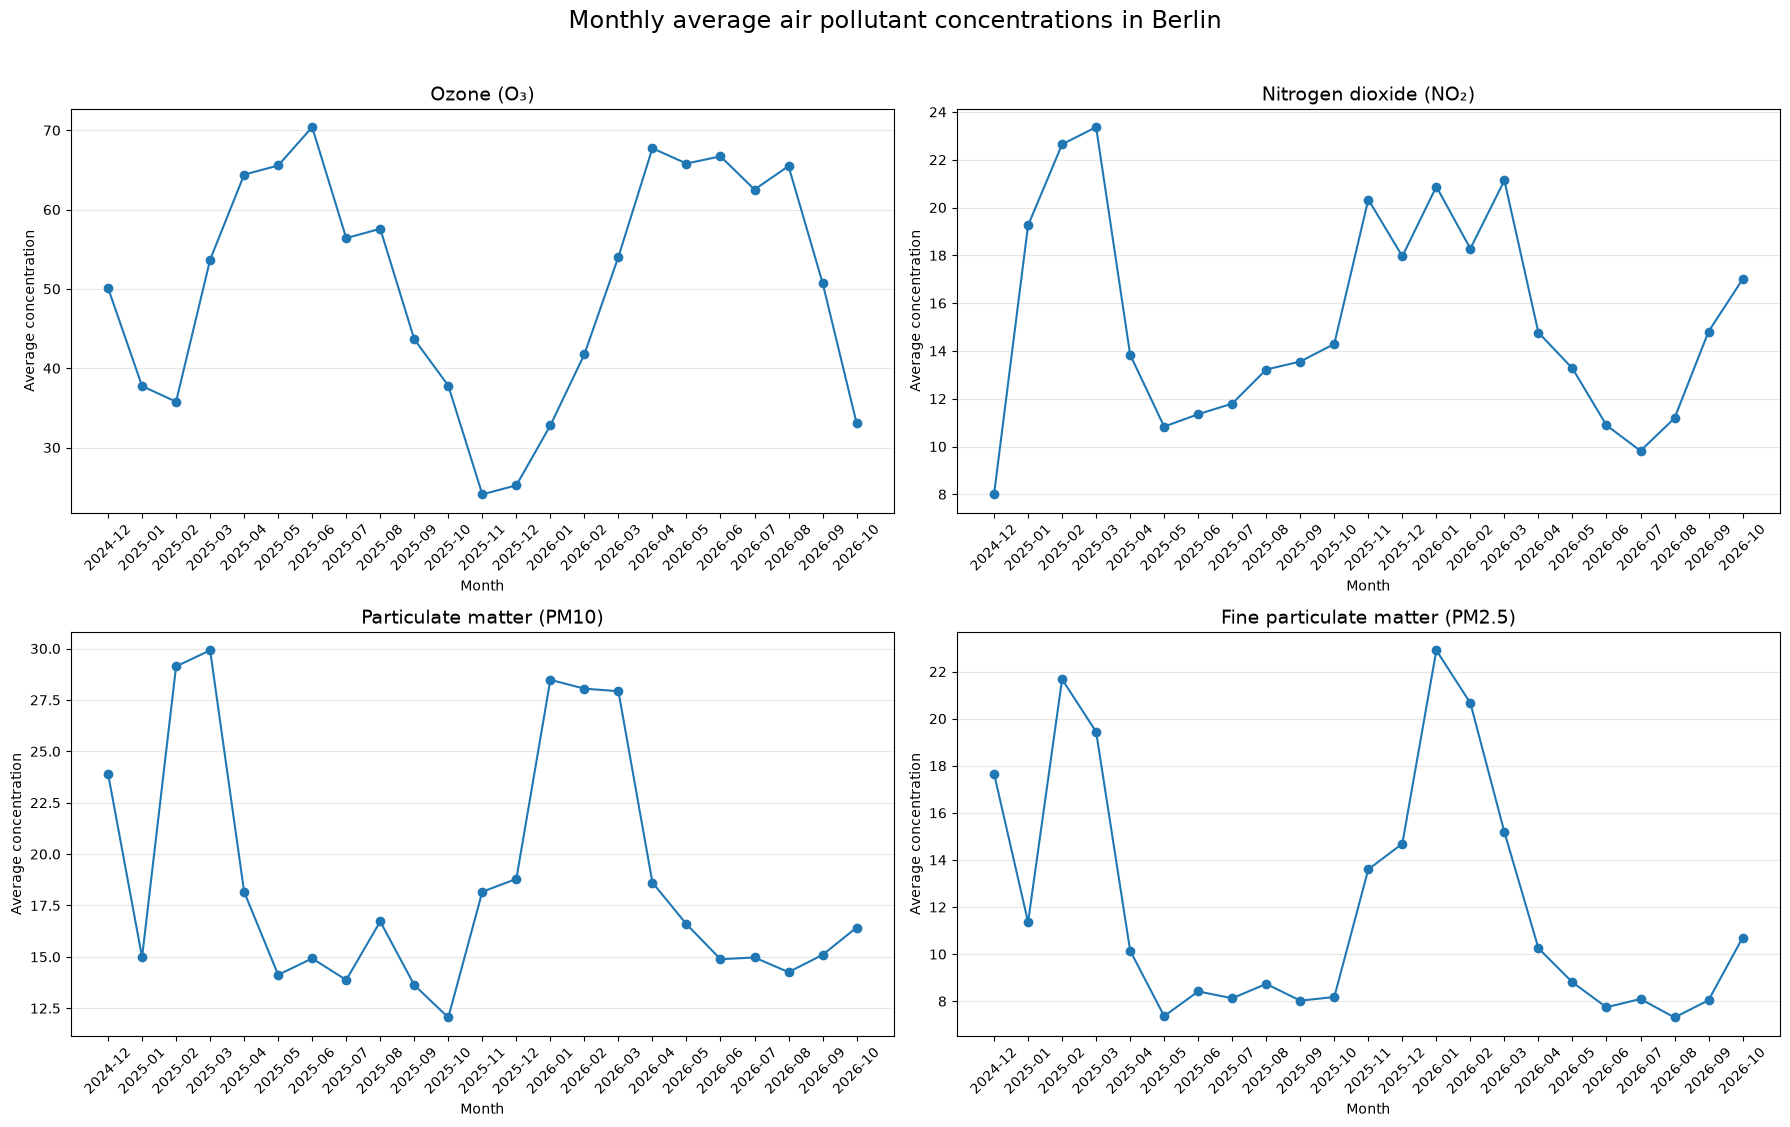

In [10]:
# Select the four main pollutants
selected_pollutants = ["o3_24h", "no2_24h", "pm10_24h", "pm2_24h"]

# Filter the dataset
air_quality_selected = air_quality_data[
    air_quality_data["component"].isin(selected_pollutants)
].copy()

# Remove timezone before extracting the calendar month
air_quality_selected["month"] = (
    air_quality_selected["datetime"]
    .dt.tz_localize(None)
    .dt.to_period("M")
)

# Calculate monthly average across available stations
monthly_air_quality = air_quality_selected.groupby(
    ["month", "component"]
).agg(
    average_value=("value", "mean"),
    observations=("value", "count"),
    stations=("station", "nunique")
).reset_index()

# Create one trend chart per pollutant
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

pollutant_titles = {
    "o3_24h": "Ozone (O₃)",
    "no2_24h": "Nitrogen dioxide (NO₂)",
    "pm10_24h": "Particulate matter (PM10)",
    "pm2_24h": "Fine particulate matter (PM2.5)"
}

for ax, pollutant in zip(axes.flatten(), selected_pollutants):

    # Select monthly data for the pollutant
    plot_data = monthly_air_quality[
        monthly_air_quality["component"] == pollutant
    ]

    # Plot monthly average
    ax.plot(
        plot_data["month"].astype(str),
        plot_data["average_value"],
        marker="o"
    )

    # Add chart labels
    ax.set_title(pollutant_titles[pollutant], fontsize=14)
    ax.set_xlabel("Month")
    ax.set_ylabel("Average concentration")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Monthly average air pollutant concentrations in Berlin",
    fontsize=17,
    y=1.02
)

plt.tight_layout()
plt.show()

- Ozone has highest level during warmer months, peaking around May, declining throughout the rest of the year for both 2025 and 2026.
- Nitrogen dioxide peaks during colder months, peaking in winter time, declining in spring and remaining relatively low in summer, with some slight increase.
- Both PM10 and PM2.5 show similar patterns: increase in winter, decline in spring/summer. PM10 shows higher values than PM2.5.

In [11]:
# Check which measurement periods are present
print(air_quality_data["period"].value_counts(dropna=False))

# Check whether a station has multiple records for the same pollutant and timestamp
duplicate_count = air_quality_data.duplicated(
    subset=["station", "component", "datetime"]
).sum()

print("Duplicate station-component-timestamp rows:", duplicate_count)

period
24h    54305
Name: count, dtype: int64
Duplicate station-component-timestamp rows: 0


In [12]:
# Create a copy for the summer analysis
air_quality_summer = air_quality_data.copy()

# Convert timestamps from UTC to Berlin local time
air_quality_summer["datetime_local"] = (
    air_quality_summer["datetime"]
    .dt.tz_convert("Europe/Berlin")
)

# Extract local date, year and month
air_quality_summer["date"] = (
    air_quality_summer["datetime_local"].dt.date
)

air_quality_summer["year"] = (
    air_quality_summer["datetime_local"].dt.year
)

air_quality_summer["month"] = (
    air_quality_summer["datetime_local"].dt.month
)

# Select the four pollutants and June–September of 2025 and 2026
selected_pollutants = ["o3_24h", "no2_24h", "pm10_24h", "pm2_24h"]

air_quality_summer = air_quality_summer[
    (air_quality_summer["component"].isin(selected_pollutants))
    & (air_quality_summer["year"].isin([2025, 2026]))
    & (air_quality_summer["month"].isin([6, 7, 8, 9]))
].copy()

# Check the resulting dataset
print("Rows:", len(air_quality_summer))
print("Date range:", air_quality_summer["date"].min(), "to",
      air_quality_summer["date"].max())

display(
    air_quality_summer.groupby(
        ["year", "component"]
    ).agg(
        observations=("value", "count"),
        stations=("station", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    ).reset_index()
)

Rows: 11378
Date range: 2025-06-01 to 2026-09-30


,year,component,observations,stations,first_date,last_date
0,2025,no2_24h,1830,15,2025-06-01,2025-09-30
1,2025,o3_24h,972,8,2025-06-01,2025-09-30
2,2025,pm10_24h,1462,12,2025-06-01,2025-09-30
3,2025,pm2_24h,1462,12,2025-06-01,2025-09-30
4,2026,no2_24h,1760,15,2026-06-01,2026-09-30
5,2026,o3_24h,954,8,2026-06-01,2026-09-30
6,2026,pm10_24h,1412,12,2026-06-01,2026-09-30
7,2026,pm2_24h,1412,12,2026-06-01,2026-09-30


In [13]:
# Count observations for each station, pollutant and year
station_coverage = air_quality_summer.groupby(
    ["component", "station", "year"]
).agg(
    observations=("value", "count")
).reset_index()

# Compare the number of observations across years
station_coverage_pivot = station_coverage.pivot(
    index=["component", "station"],
    columns="year",
    values="observations"
).fillna(0).astype(int)

# Display station-level coverage
display(station_coverage_pivot)

year               2025  2026
component station            
no2_24h   mc010     122   122
          mc027     122   121
          mc032     122   121
          mc042     122   112
          mc077     122   122
          mc085     122   122
          mc117     122    92
          mc124     122   110
          mc144     122   122
          mc145     122   122
          mc171     122   120
          mc174     122   114
          mc190     122   122
          mc221     122   122
          mc282     122   116
o3_24h    mc010     122   122
          mc027     122   121
          mc032     118   121
          mc042     122   112
          mc077     122   122
          mc085     122   122
          mc145     122   121
          mc174     122   113
pm10_24h  mc010     122   122
          mc032     122   122
          mc042     122   119
          mc077     122   122
          mc085     122   118
          mc117     122    92
          mc124     122   119
          mc144     122   115
          mc171     122   119
          mc174     122   120
          mc190     122   122
          mc221     120   122
pm2_24h   mc010     122   122
          mc032     122   122
          mc042     122   119
          mc077     122   122
          mc085     122   118
          mc117     122    92
          mc124     122   119
          mc144     122   115
          mc171     122   119
          mc174     122   120
          mc190     122   122
          mc221     120   122

In [14]:
# Calculate the percentage of days covered by each station
station_coverage_pivot["coverage_2025"] = (
    station_coverage_pivot[2025] / 122 * 100
)

station_coverage_pivot["coverage_2026"] = (
    station_coverage_pivot[2026] / 122 * 100
)

# Retain stations with at least 90% coverage in both years
station_coverage_pivot["keep_station"] = (
    (station_coverage_pivot["coverage_2025"] >= 90)
    & (station_coverage_pivot["coverage_2026"] >= 90)
)

# Display the stations retained for each pollutant
display(
    station_coverage_pivot[
        ["coverage_2025", "coverage_2026", "keep_station"]
    ].round(1)
)

year               coverage_2025  coverage_2026  keep_station
component station                                            
no2_24h   mc010            100.0          100.0          True
          mc027            100.0           99.2          True
          mc032            100.0           99.2          True
          mc042            100.0           91.8          True
          mc077            100.0          100.0          True
          mc085            100.0          100.0          True
          mc117            100.0           75.4         False
          mc124            100.0           90.2          True
          mc144            100.0          100.0          True
          mc145            100.0          100.0          True
          mc171            100.0           98.4          True
          mc174            100.0           93.4          True
          mc190            100.0          100.0          True
          mc221            100.0          100.0          True
          mc282            100.0           95.1          True
o3_24h    mc010            100.0          100.0          True
          mc027            100.0           99.2          True
          mc032             96.7           99.2          True
          mc042            100.0           91.8          True
          mc077            100.0          100.0          True
          mc085            100.0          100.0          True
          mc145            100.0           99.2          True
          mc174            100.0           92.6          True
pm10_24h  mc010            100.0          100.0          True
          mc032            100.0          100.0          True
          mc042            100.0           97.5          True
          mc077            100.0          100.0          True
          mc085            100.0           96.7          True
          mc117            100.0           75.4         False
          mc124            100.0           97.5          True
          mc144            100.0           94.3          True
          mc171            100.0           97.5          True
          mc174            100.0           98.4          True
          mc190            100.0          100.0          True
          mc221             98.4          100.0          True
pm2_24h   mc010            100.0          100.0          True
          mc032            100.0          100.0          True
          mc042            100.0           97.5          True
          mc077            100.0          100.0          True
          mc085            100.0           96.7          True
          mc117            100.0           75.4         False
          mc124            100.0           97.5          True
          mc144            100.0           94.3          True
          mc171            100.0           97.5          True
          mc174            100.0           98.4          True
          mc190            100.0          100.0          True
          mc221             98.4          100.0          True

Excluding station Mc117 from the analysis as contains too many missing values for 2026

In [15]:
# Identify stations that meet the coverage threshold
eligible_stations = (
    station_coverage_pivot[
        station_coverage_pivot["keep_station"]
    ]
    .reset_index()[["component", "station"]]
)

# Keep only eligible stations
air_quality_balanced = air_quality_summer.merge(
    eligible_stations,
    on=["component", "station"],
    how="inner"
)

# Calculate daily values for each station
station_daily = air_quality_balanced.groupby(
    ["date", "year", "component", "station"]
).agg(
    station_value=("value", "mean")
).reset_index()

# Calculate the equal-weighted daily average across stations
daily_air_quality = station_daily.groupby(
    ["date", "year", "component"]
).agg(
    average_value=("station_value", "mean"),
    stations_reporting=("station", "nunique")
).reset_index()

# Check the resulting daily dataset
display(
    daily_air_quality.groupby(
        ["year", "component"]
    ).agg(
        days=("date", "nunique"),
        average_concentration=("average_value", "mean"),
        min_stations=("stations_reporting", "min"),
        max_stations=("stations_reporting", "max")
    ).round(2).reset_index()
)

,year,component,days,average_concentration,min_stations,max_stations
0,2025,no2_24h,122,12.47,14,14
1,2025,o3_24h,122,57.45,8,8
2,2025,pm10_24h,122,14.92,11,11
3,2025,pm2_24h,122,8.33,11,11
4,2026,no2_24h,122,11.55,14,14
5,2026,o3_24h,122,61.81,8,8
6,2026,pm10_24h,122,14.84,11,11
7,2026,pm2_24h,122,7.80,11,11


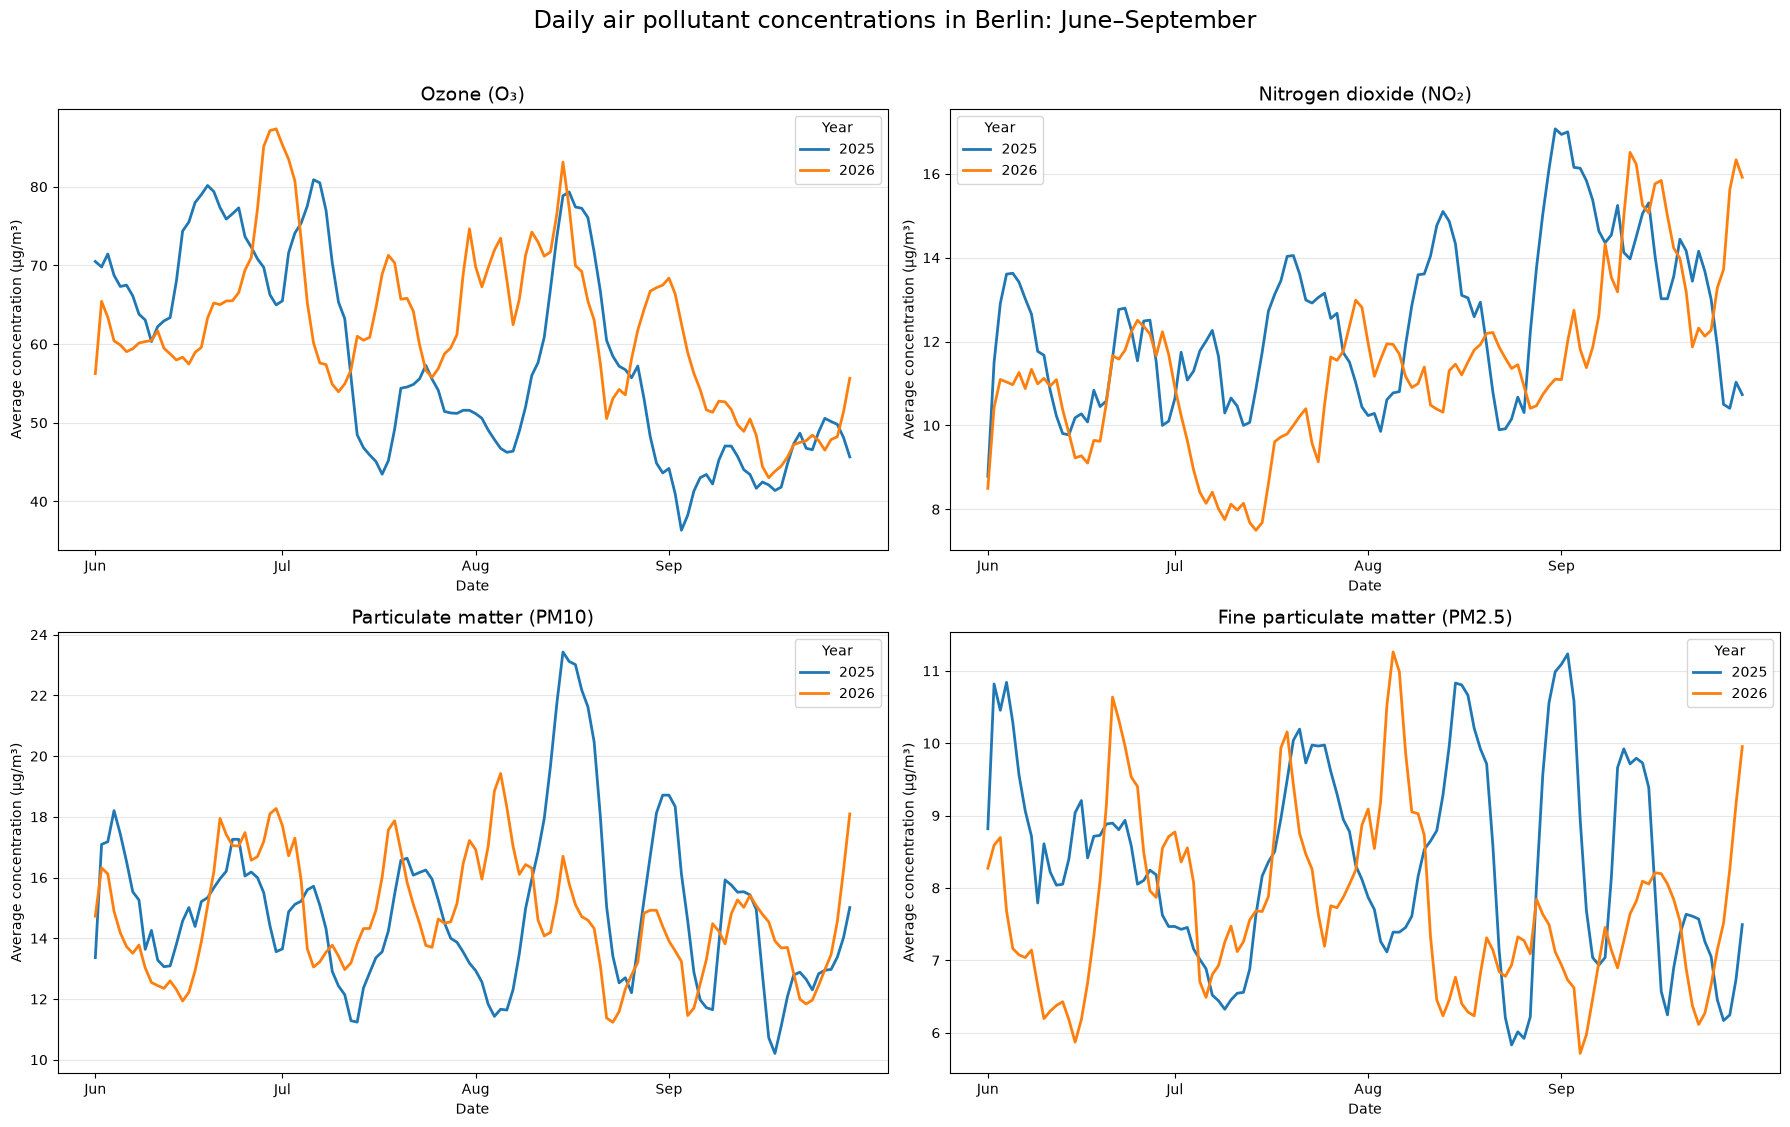

In [56]:
# Sort observations by date
daily_air_quality = daily_air_quality.sort_values("date").copy()

# Create a month-day label to align the two years
daily_air_quality["month_day"] = pd.to_datetime(
    daily_air_quality["date"]
).dt.strftime("%m-%d")

# Calculate a 7-day rolling average separately for each year and pollutant
daily_air_quality["rolling_7d"] = (
    daily_air_quality.groupby(["year", "component"])["average_value"]
    .transform(lambda x: x.rolling(window=7, min_periods=1).mean())
)

# Define chart titles
pollutant_titles = {
    "o3_24h": "Ozone (O₃)",
    "no2_24h": "Nitrogen dioxide (NO₂)",
    "pm10_24h": "Particulate matter (PM10)",
    "pm2_24h": "Fine particulate matter (PM2.5)"
}

# Create four charts
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

for ax, pollutant in zip(axes.flatten(), selected_pollutants):

    # Filter data for the current pollutant
    plot_data = daily_air_quality[
        daily_air_quality["component"] == pollutant
    ]

    # Plot each year
    for year in [2025, 2026]:
        year_data = plot_data[
            plot_data["year"] == year
        ].sort_values("date")

        # Plot daily averages - removed for better visualization
        '''ax.plot(
            year_data["month_day"],
            year_data["average_value"],
            alpha=0.25,
            linewidth=0.8
        )'''

        # Plot 7-day rolling average
        ax.plot(
            year_data["month_day"],
            year_data["rolling_7d"],
            label=str(year),
            linewidth=2
        )

    # Add chart labels
    ax.set_title(pollutant_titles[pollutant], fontsize=14)
    ax.set_xlabel("Date")
    ax.set_ylabel("Average concentration (µg/m³)")

     # Show only one label per month
    ax.set_xticks(["06-01", "07-01", "08-01", "09-01"])
    ax.set_xticklabels(["Jun", "Jul", "Aug", "Sep"])

    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Daily air pollutant concentrations in Berlin: June–September",
    fontsize=17,
    y=1.02
)

plt.tight_layout()
plt.show()

- Ozone (O₃):Peaks during end June/early July and mid-August in 2026, with a broadly similar pattern in 2025.
- Nitrogen dioxide (NO₂):Relatively low concentrations during summer, with the lowest values around July and an increase towards September.
- PM10:Fluctuating concentrations in both years, with a noticeable peak around mid-August 2025.
- PM2.5:Also fluctuates throughout summer. Two peaks can be observed in August and September 2025, and one in August 2026.

In [26]:
#importing weather dataset to check average pollutant concentrations on hot days versus non-hot days

weather_combined = pd.read_csv("merged_complete_datasets/df_weather_combined_all.csv")

In [28]:
# Inspect the weather dataset
print(weather_combined.columns.tolist())
print(weather_combined.dtypes)

# Display a few records
display(weather_combined.head())

['Unnamed: 0', 'station_id', 'date', 'tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'tsun', 'cloud_cover', 'pres_dwd', 'station', 'source', 'pres_meteostat']
Unnamed: 0          int64
station_id        float64
date                  str
tavg              float64
tmin              float64
tmax              float64
prcp              float64
wspd              float64
tsun              float64
cloud_cover       float64
pres_dwd          float64
station               str
source                str
pres_meteostat    float64
dtype: object


,Unnamed: 0,station_id,date,tavg,tmin,tmax,prcp,wspd,tsun,cloud_cover,pres_dwd,station,source,pres_meteostat
0,0,427.0,2025-04-09 00:00:00,8.9,1.8,15.4,0.0,12.96,NaN,NaN,1015.8,Berlin Brandenburg,DWD,NaN
1,1,427.0,2025-04-10 00:00:00,9.1,5.1,14.0,0.0,19.08,NaN,5.3,1016.4,Berlin Brandenburg,DWD,NaN
2,2,427.0,2025-04-11 00:00:00,9.7,4.9,14.8,0.0,21.60,NaN,7.2,1009.7,Berlin Brandenburg,DWD,NaN
3,3,427.0,2025-04-12 00:00:00,11.1,4.3,17.4,0.0,7.92,NaN,4.5,1007.9,Berlin Brandenburg,DWD,NaN
4,4,427.0,2025-04-13 00:00:00,14.8,6.8,22.8,0.0,15.12,NaN,4.5,1000.6,Berlin Brandenburg,DWD,NaN


In [ ]:
# Convert date to datetime
weather_combined["date"] = pd.to_datetime(weather_combined["date"])

# Remove the saved DataFrame index column
weather_combined = weather_combined.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Select the five DWD stations - For Meteostat, we will need to gather also 2025 data
dwd_stations = [
    "Berlin Brandenburg",
    "Buch",
    "Dahlem",
    "Marzahn",
    "Tempelhof"
]

# Filter for DWD stations and June–September 2025 and 2026
weather_summer = weather_combined[
    (weather_combined["source"] == "DWD")
    & (weather_combined["station"].isin(dwd_stations))
    & (weather_combined["date"].dt.year.isin([2025, 2026]))
    & (weather_combined["date"].dt.month.isin([6, 7, 8, 9]))
].copy()

# Calculate the average maximum temperature across stations for each day
daily_temperature = weather_summer.groupby(
    "date"
).agg(
    average_tmax=("tmax", "mean"),
    stations_reporting=("station", "nunique")
).reset_index()

# Add year
daily_temperature["year"] = daily_temperature["date"].dt.year

# Check the results
display(
    daily_temperature.groupby("year").agg(
        days=("date", "nunique"),
        average_tmax=("average_tmax", "mean"),
        min_stations=("stations_reporting", "min"),
        max_stations=("stations_reporting", "max")
    ).round(2)
)

,days,average_tmax,min_stations,max_stations
year,,,,
2025,122,23.96,5,5
2026,122,24.96,5,5


In [30]:
# Classify days based on average maximum temperature
daily_temperature["day_type"] = daily_temperature[
    "average_tmax"
].apply(
    lambda x: "Hot day" if x > 30 else "Non-hot day"
)

# Check the number of hot and non-hot days per year
display(
    daily_temperature.groupby(
        ["year", "day_type"]
    ).agg(
        days=("date", "count"),
        average_tmax=("average_tmax", "mean")
    ).round(2).reset_index()
)

,year,day_type,days,average_tmax
0,2025,Hot day,9,33.35
1,2025,Non-hot day,113,23.21
2,2026,Hot day,18,33.26
3,2026,Non-hot day,104,23.52


In [32]:
# Convert both date columns to datetime
daily_air_quality["date"] = pd.to_datetime(
    daily_air_quality["date"]
)

daily_temperature["date"] = pd.to_datetime(
    daily_temperature["date"]
)

# Verify data types
print("Air quality:", daily_air_quality["date"].dtype)
print("Temperature:", daily_temperature["date"].dtype)

Air quality: datetime64[s]
Temperature: datetime64[us]


In [33]:
# Merge daily temperature and air-quality data
temperature_air_quality = daily_air_quality.merge(
    daily_temperature[
        ["date", "average_tmax", "day_type"]
    ],
    on="date",
    how="inner"
)

# Check the merged dataset
print("Rows:", len(temperature_air_quality))

display(temperature_air_quality.head())

# Check coverage by year and pollutant
display(
    temperature_air_quality.groupby(
        ["year", "component"]
    ).agg(
        days=("date", "nunique"),
        average_tmax=("average_tmax", "mean")
    ).round(2).reset_index()
)

Rows: 976


,date,year,component,average_value,stations_reporting,month_day,rolling_7d,average_tmax,day_type
0,2025-06-01,2025,no2_24h,8.785714,14,06-01,8.785714,26.94,Non-hot day
1,2025-06-01,2025,o3_24h,70.500000,8,06-01,70.500000,26.94,Non-hot day
2,2025-06-01,2025,pm10_24h,13.363636,11,06-01,13.363636,26.94,Non-hot day
3,2025-06-01,2025,pm2_24h,8.818182,11,06-01,8.818182,26.94,Non-hot day
4,2025-06-02,2025,no2_24h,14.214286,14,06-02,11.500000,22.60,Non-hot day


,year,component,days,average_tmax
0,2025,no2_24h,122,23.96
1,2025,o3_24h,122,23.96
2,2025,pm10_24h,122,23.96
3,2025,pm2_24h,122,23.96
4,2026,no2_24h,122,24.96
5,2026,o3_24h,122,24.96
6,2026,pm10_24h,122,24.96
7,2026,pm2_24h,122,24.96


In [34]:
# Compare pollutant concentrations by day type and year
pollutant_comparison = temperature_air_quality.groupby(
    ["year", "component", "day_type"]
).agg(
    days=("date", "nunique"),
    average_concentration=("average_value", "mean"),
    median_concentration=("average_value", "median"),
    std_dev=("average_value", "std")
).reset_index()

# Display the results
display(
    pollutant_comparison.round(2)
)

,year,component,day_type,days,average_concentration,median_concentration,std_dev
0,2025,no2_24h,Hot day,9,13.98,13.93,3.26
1,2025,no2_24h,Non-hot day,113,12.35,12.00,3.58
2,2025,o3_24h,Hot day,9,88.22,93.00,12.59
3,2025,o3_24h,Non-hot day,113,55.00,53.50,13.61
4,2025,pm10_24h,Hot day,9,21.80,19.18,6.49
5,2025,pm10_24h,Non-hot day,113,14.38,13.45,3.96
6,2025,pm2_24h,Hot day,9,10.31,10.18,2.76
7,2025,pm2_24h,Non-hot day,113,8.17,7.73,2.50
8,2026,no2_24h,Hot day,18,12.55,13.13,2.45
9,2026,no2_24h,Non-hot day,104,11.38,10.68,3.81


- Ozone: higher avg concentration in hotter days
- Nitrogen Dioxide: smaller difference, avg concentration slightly higher on hotter days
- PM10: higher concentration in hot days for both years
- PM2.5: slightly higher in hot days for both years

In [41]:
# Keep only the average concentrations and relevant categories
plot_data = pollutant_comparison[
    ["year", "component", "day_type", "average_concentration"]
].copy()

# Define the order of pollutants and temperature categories
pollutant_order = ["no2_24h", "o3_24h", "pm10_24h", "pm2_24h"]
day_order = ["Hot day", "Non-hot day"]

# Check the prepared data
display(plot_data)

,year,component,day_type,average_concentration
0,2025,no2_24h,Hot day,13.976190
1,2025,no2_24h,Non-hot day,12.352086
2,2025,o3_24h,Hot day,88.224206
3,2025,o3_24h,Non-hot day,55.001738
4,2025,pm10_24h,Hot day,21.797980
5,2025,pm10_24h,Non-hot day,14.375543
6,2025,pm2_24h,Hot day,10.313131
7,2025,pm2_24h,Non-hot day,8.167900
8,2026,no2_24h,Hot day,12.553003
9,2026,no2_24h,Non-hot day,11.375475


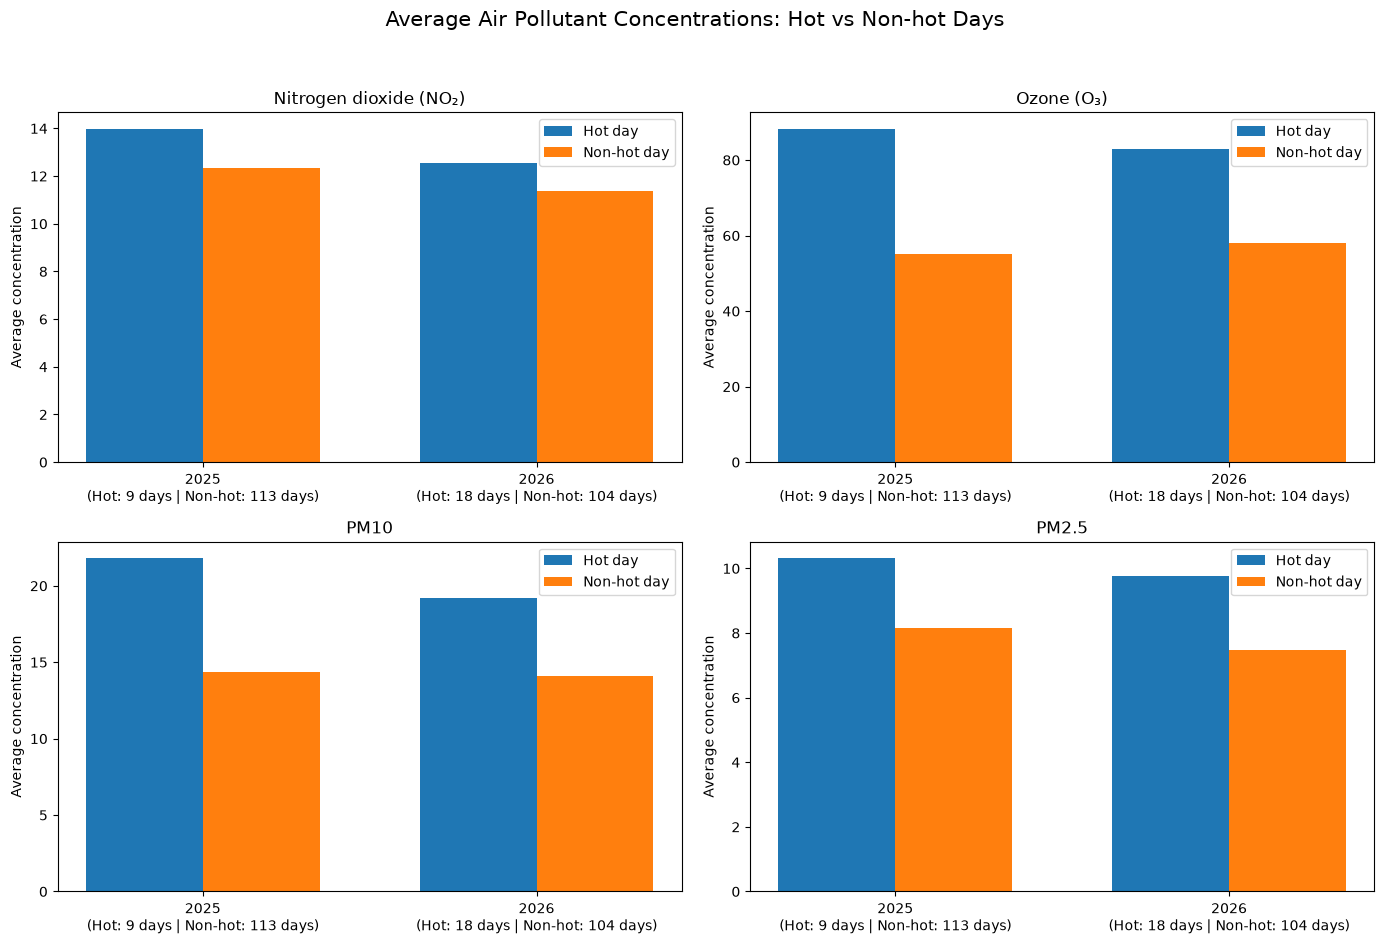

In [ ]:
import numpy as np

# Define chart layout and categories
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

pollutant_order = ["no2_24h", "o3_24h", "pm10_24h", "pm2_24h"]
pollutant_names = {
    "no2_24h": "Nitrogen dioxide (NO₂)",
    "o3_24h": "Ozone (O₃)",
    "pm10_24h": "PM10",
    "pm2_24h": "PM2.5"
}

years = [2025, 2026]
day_order = ["Hot day", "Non-hot day"]

x = np.arange(len(years))
width = 0.35

# Create one subplot per pollutant
for ax, pollutant in zip(axes, pollutant_order):

    pollutant_data = plot_data[
        plot_data["component"] == pollutant
    ]

    hot_values = [
        pollutant_data[
            (pollutant_data["year"] == year)
            & (pollutant_data["day_type"] == "Hot day")
        ]["average_concentration"].iloc[0]
        for year in years
    ]

    non_hot_values = [
        pollutant_data[
            (pollutant_data["year"] == year)
            & (pollutant_data["day_type"] == "Non-hot day")
        ]["average_concentration"].iloc[0]
        for year in years
    ]

    # Plot grouped bars
    ax.bar(x - width/2, hot_values, width, label="Hot day")
    ax.bar(x + width/2, non_hot_values, width, label="Non-hot day")

    # Add titles and labels
    ax.set_title(pollutant_names[pollutant])
    ax.set_xticks(x)
    # Add the number of observations below each year
    ax.set_xticklabels([ #indicating avg concentration for hot days is based using 9 days, while the non-hot 113
    "2025\n(Hot: 9 days | Non-hot: 113 days)",
    "2026\n(Hot: 18 days | Non-hot: 104 days)"
])
    ax.set_ylabel("Average concentration")
    ax.legend()

# Improve spacing and display
fig.suptitle(
    "Average Air Pollutant Concentrations: Hot vs Non-hot Days",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

In [ ]:
# Extract the month for each observation
temperature_air_quality["month"] = (
    temperature_air_quality["date"].dt.month
)

# Calculate the 75th percentile for each pollutant and month to define the pollution thresholds
pollution_thresholds = temperature_air_quality.groupby(
    ["component", "month"]
).agg(
    high_threshold=("average_value", lambda x: x.quantile(0.75))
).reset_index()

# Display the thresholds
display(pollution_thresholds.round(2))

,component,month,high_threshold
0,no2_24h,6,12.88
1,no2_24h,7,13.84
2,no2_24h,8,14.98
3,no2_24h,9,16.61
4,o3_24h,6,74.75
5,o3_24h,7,65.91
6,o3_24h,8,71.06
7,o3_24h,9,54.66
8,pm10_24h,6,17.36
9,pm10_24h,7,16.73


High pollution threshold: all average values above the 75th percentile

This is just to find high pollutant concentrations in the dataset, it is not a legal limit

In [36]:
# Merge monthly thresholds into the daily dataset
temperature_air_quality = temperature_air_quality.merge(
    pollution_thresholds,
    on=["component", "month"],
    how="left"
)

# Classify each day based on its pollutant concentration
temperature_air_quality["pollution_level"] = (
    temperature_air_quality["average_value"]
    .gt(temperature_air_quality["high_threshold"])
    .map({True: "High", False: "Not high"})
)

# Check the classification
display(
    temperature_air_quality[
        ["date", "year", "component", "average_value",
         "high_threshold", "pollution_level"]
    ].head(12)
)

,date,year,component,average_value,high_threshold,pollution_level
0,2025-06-01,2025,no2_24h,8.785714,12.884740,Not high
1,2025-06-01,2025,o3_24h,70.500000,74.750000,Not high
2,2025-06-01,2025,pm10_24h,13.363636,17.363636,Not high
3,2025-06-01,2025,pm2_24h,8.818182,9.304545,Not high
4,2025-06-02,2025,no2_24h,14.214286,12.884740,High
5,2025-06-02,2025,o3_24h,69.125000,74.750000,Not high
6,2025-06-02,2025,pm10_24h,20.818182,17.363636,High
7,2025-06-02,2025,pm2_24h,12.818182,9.304545,High
8,2025-06-03,2025,no2_24h,15.714286,12.884740,High
9,2025-06-03,2025,o3_24h,74.750000,74.750000,Not high


In [37]:
# Count high and non-high days by year, pollutant and temperature category
high_pollution_summary = temperature_air_quality.groupby(
    ["year", "component", "day_type", "pollution_level"]
).agg(
    days=("date", "nunique")
).reset_index()

# Display the results
display(high_pollution_summary)

,year,component,day_type,pollution_level,days
0,2025,no2_24h,Hot day,High,6
1,2025,no2_24h,Hot day,Not high,3
2,2025,no2_24h,Non-hot day,High,34
3,2025,no2_24h,Non-hot day,Not high,79
4,2025,o3_24h,Hot day,High,8
5,2025,o3_24h,Hot day,Not high,1
6,2025,o3_24h,Non-hot day,High,14
7,2025,o3_24h,Non-hot day,Not high,99
8,2025,pm10_24h,Hot day,High,7
9,2025,pm10_24h,Hot day,Not high,2


In [40]:
# Count high and non-high days by year, pollutant and temperature category
high_pollution_summary = temperature_air_quality.groupby(
    ["year", "component", "day_type", "pollution_level"]
).agg(
    days=("date", "nunique")
).reset_index()


# Reshape the table: High and Not high become separate columns
high_pollution_pivot = high_pollution_summary.pivot_table(
    index=["year", "component", "day_type"],
    columns="pollution_level",
    values="days",
    fill_value=0
).reset_index()


# Remove the unnecessary column index name
high_pollution_pivot.columns.name = None


# Calculate the total number of days
high_pollution_pivot["total_days"] = (
    high_pollution_pivot["High"]
    + high_pollution_pivot["Not high"]
)


# Calculate the percentage of high-pollution days
high_pollution_pivot["high_percentage"] = (
    high_pollution_pivot["High"]
    / high_pollution_pivot["total_days"] * 100
)


# Round the results
high_pollution_pivot = high_pollution_pivot.round(1)


# Display the final table
display(high_pollution_pivot)

,year,component,day_type,High,Not high,total_days,high_percentage
0,2025,no2_24h,Hot day,6.0,3.0,9.0,66.7
1,2025,no2_24h,Non-hot day,34.0,79.0,113.0,30.1
2,2025,o3_24h,Hot day,8.0,1.0,9.0,88.9
3,2025,o3_24h,Non-hot day,14.0,99.0,113.0,12.4
4,2025,pm10_24h,Hot day,7.0,2.0,9.0,77.8
5,2025,pm10_24h,Non-hot day,21.0,92.0,113.0,18.6
6,2025,pm2_24h,Hot day,6.0,3.0,9.0,66.7
7,2025,pm2_24h,Non-hot day,25.0,88.0,113.0,22.1
8,2026,no2_24h,Hot day,5.0,13.0,18.0,27.8
9,2026,no2_24h,Non-hot day,17.0,87.0,104.0,16.3


In [48]:
# Keep the columns needed for the visualization
plot_data = high_pollution_pivot[
    ["year", "component", "day_type", "high_percentage"]
].copy()

# Define the display order
pollutant_order = ["no2_24h", "o3_24h", "pm10_24h", "pm2_24h"]

In [49]:
display(plot_data.head())

,year,component,day_type,high_percentage
0,2025,no2_24h,Hot day,66.7
1,2025,no2_24h,Non-hot day,30.1
2,2025,o3_24h,Hot day,88.9
3,2025,o3_24h,Non-hot day,12.4
4,2025,pm10_24h,Hot day,77.8


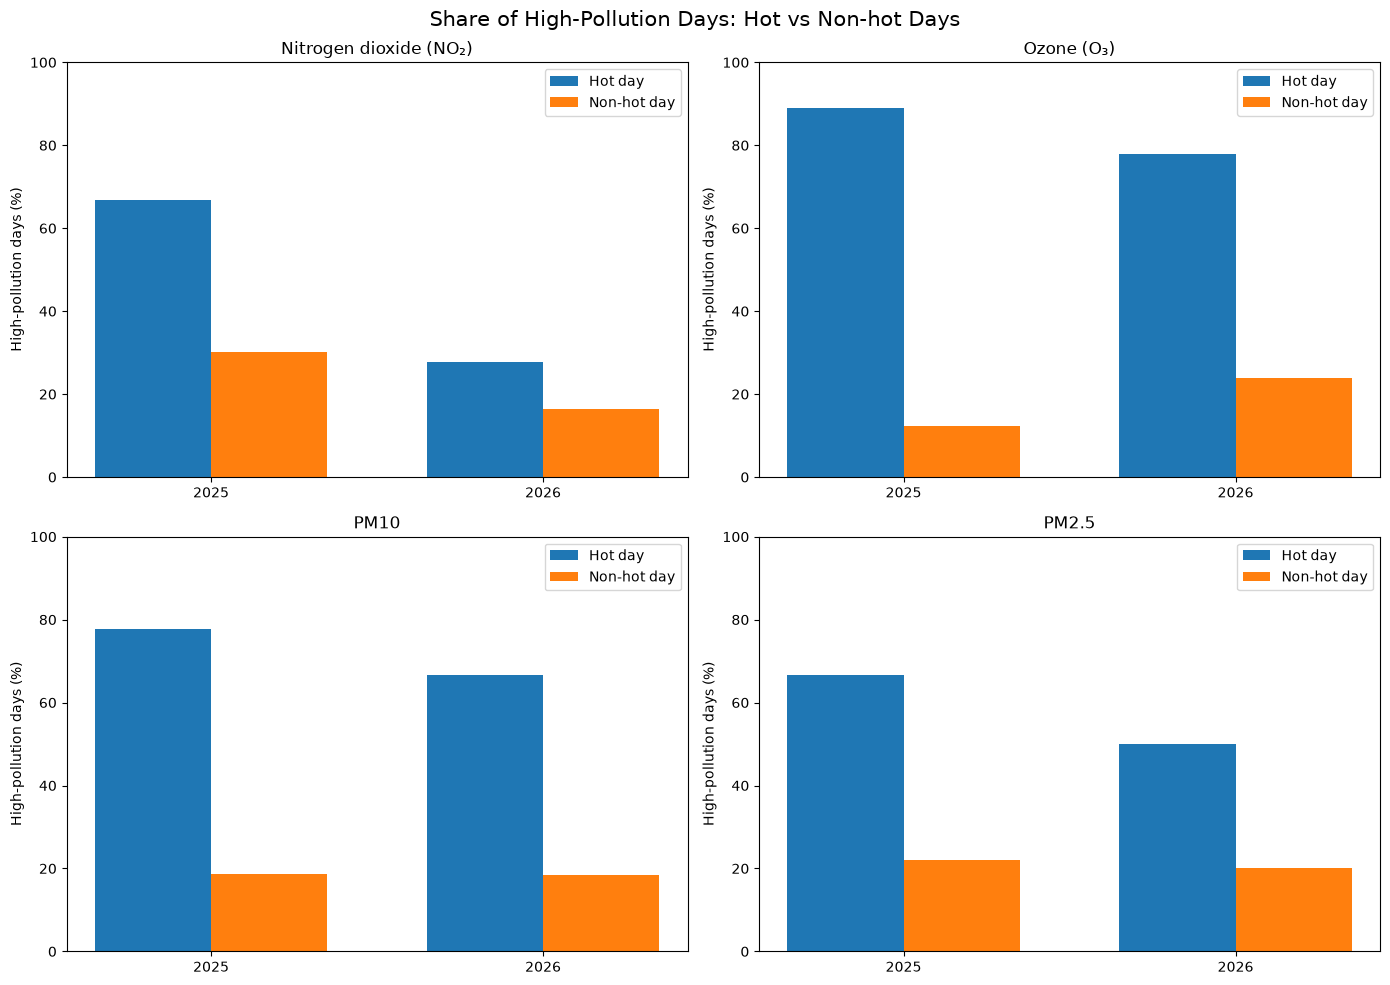

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

pollutant_order = ["no2_24h", "o3_24h", "pm10_24h", "pm2_24h"]

pollutant_names = {
    "no2_24h": "Nitrogen dioxide (NO₂)",
    "o3_24h": "Ozone (O₃)",
    "pm10_24h": "PM10",
    "pm2_24h": "PM2.5"
}

years = [2025, 2026]
x = np.arange(len(years))
width = 0.35

for ax, pollutant in zip(axes, pollutant_order):

    pollutant_data = plot_data[
        plot_data["component"] == pollutant
    ]

    hot_values = [
        pollutant_data[
            (pollutant_data["year"] == year)
            & (pollutant_data["day_type"] == "Hot day")
        ]["high_percentage"].iloc[0]
        for year in years
    ]

    non_hot_values = [
        pollutant_data[
            (pollutant_data["year"] == year)
            & (pollutant_data["day_type"] == "Non-hot day")
        ]["high_percentage"].iloc[0]
        for year in years
    ]

    # Draw the bars
    ax.bar(x - width/2, hot_values, width, label="Hot day")
    ax.bar(x + width/2, non_hot_values, width, label="Non-hot day")

    # Format each subplot
    ax.set_title(pollutant_names[pollutant])
    ax.set_xticks(x)
    ax.set_xticklabels(years)
    ax.set_ylim(0, 100)
    ax.set_ylabel("High-pollution days (%)")
    ax.legend()

fig.suptitle(
    "Share of High-Pollution Days: Hot vs Non-hot Days",
    fontsize=15
)

plt.tight_layout()
plt.show()

Hot days have a higher share of high pollution days compared to non hot days:
- Ozone and PM10 are considerably higher during hot days compared to non hot ones
- Nitrogen Dioxide high pollution days decreased significantly in 2026, the concentration is still higher on hotter days
- PM2.5 high pollution days slightly decreased in 2026, the concentration remains higher on hot days 

In [53]:
#checking days with high concentrations of pm10 and pm2.5

# Filter PM10 and PM2.5 exceedances across both summers
exceedance_days = temperature_air_quality[
    (
        (temperature_air_quality["component"] == "pm10_24h")
        & (temperature_air_quality["average_value"] > 50)
    )
    |
    (
        (temperature_air_quality["component"] == "pm2_24h")
        & (temperature_air_quality["average_value"] > 25)
    )
].copy()

# Display individual exceedance dates
exceedance_days = exceedance_days[
    ["date", "year", "component", "average_value", "average_tmax", "day_type"]
].sort_values(["year", "component", "date"])

display(exceedance_days)

,date,year,component,average_value,average_tmax,day_type


In [54]:
# Check the highest daily average for each pollutant and year
maximum_values = temperature_air_quality[
    temperature_air_quality["component"].isin(["pm10_24h", "pm2_24h"])
].groupby(
    ["year", "component"]
).agg(
    maximum_daily_average=("average_value", "max"),
    date_of_maximum=("average_value", lambda x: temperature_air_quality.loc[x.idxmax(), "date"])
).reset_index()

display(maximum_values)

,year,component,maximum_daily_average,date_of_maximum
0,2025,pm10_24h,33.272727,2025-08-15
1,2025,pm2_24h,17.909091,2025-08-28
2,2026,pm10_24h,26.000000,2026-06-28
3,2026,pm2_24h,15.636364,2026-06-21


Maximum average values of PM10 and PM2.5 can be found during summer months. According to the Berlin air quality network, levels from 35 to 50 for PM10 and from 20 to 25 for pm2.5 are considered sufficient